In [ ]:
import pandas as pd
from google.colab import files

# 1. 엑셀 파일 업로드
print("📁 엑셀 파일(NewsResult_20250701-20251231 (1).xlsx)을 업로드해주세요.")
uploaded = files.upload()

# 파일명 지정 (업로드한 파일 이름)
file_name = list(uploaded.keys())[0]

# 2. 데이터 불러오기
df = pd.read_excel(file_name)
print(f"\n원본 데이터 기사 수: {len(df)}건")

# -------------------------------------------------------------
# 3. 중복 기사 제거 작업
# -------------------------------------------------------------

# [방법 1] 제목(제목) 기준 중복 제거 (첫 번째 기사만 남김)
df_dedup_title = df.drop_duplicates(subset=['제목'], keep='first')

# [방법 2] 제목과 본문 앞부분(앞 100자)까지 동일한 완전 중복 제거
# (동일한 제목이어도 내용이 살짝 다른 최신보 등이 있을 경우 대비)
df['본문_초반'] = df['본문'].astype(str).str.slice(0, 100)
df_dedup_strict = df.drop_duplicates(subset=['제목', '본문_초반'], keep='first')
df_dedup_strict = df_dedup_strict.drop(columns=['본문_초반']) # 임시 칼럼 삭제

print("\n--- [중복 제거 결과 Summary] ---")
print(f"• '제목' 기준 중복 제거 후 남은 기사 수: {len(df_dedup_title)}건 (제거된 중복: {len(df) - len(df_dedup_title)}건)")
print(f"• '제목 + 본문 앞부분' 기준 중복 제거 후 남은 기사 수: {len(df_dedup_strict)}건")

# -------------------------------------------------------------
# 4. 정제된 데이터 엑셀로 저장 및 자동 다운로드
# -------------------------------------------------------------
# 제목 기준 중복을 제거한 데이터를 최종 저장 데이터로 선택
output_filename = "NewsResult_Deduplicated.xlsx"
df_dedup_title.to_excel(output_filename, index=False)

print(f"\n✅ 중복이 제거된 파일이 '{output_filename}'으로 저장되었습니다.")

# 코랩에서 로컬 PC로 자동 다운로드 실행
files.download(output_filename)

📁 엑셀 파일(NewsResult_20250701-20251231 (1).xlsx)을 업로드해주세요.


Saving NewsResult_20250701-20251231 (1).xlsx to NewsResult_20250701-20251231 (1).xlsx

원본 데이터 기사 수: 74건

--- [중복 제거 결과 Summary] ---
• '제목' 기준 중복 제거 후 남은 기사 수: 74건 (제거된 중복: 0건)
• '제목 + 본문 앞부분' 기준 중복 제거 후 남은 기사 수: 74건

✅ 중복이 제거된 파일이 'NewsResult_Deduplicated.xlsx'으로 저장되었습니다.


/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# 1. 필수 라이브러리 설치 및 불러오기
!pip install konlpy openpyxl -q

import pandas as pd
import re
from google.colab import files
from konlpy.tag import Okt

print("📁 'NewsResult_Deduplicated.xlsx' 파일을 업로드해주세요.")
uploaded = files.upload()
file_name = list(uploaded.keys())[0]

# 데이터 로드
df = pd.read_excel(file_name)
print(f"총 {len(df)}건의 기사 데이터를 불러왔습니다.")

# -------------------------------------------------------------
# 2. 인명/지명/국가/불용어 사전 및 매핑 정의
# -------------------------------------------------------------

# (1) 성과 이름을 하나로 통합할 주요 인명 매핑 사전
name_map = {
    r'도널드\s*트럼프|트럼프': '도널드_트럼프',
    r'블라디미르\s*푸틴|푸틴': '블라디미르_푸틴',
    r'볼로디미르\s*젤렌스키|젤렌스키': '볼로디미르_젤렌스키',
    r'조\s*바이든|바이든': '조_바이든',
    r'시진핑|시\s*진핑': '시진핑',
    r'김정은|김\s*정은': '김정은',
    r'윤석열|윤\s*석열': '윤석열',
    r'세르게이\s*쇼이구|쇼이구': '세르게이_쇼이구',
    r'세르게이\s*라브로프|라브로프': '세르게이_라브로프',
    r'빅토르\s*오르반|오르반': '빅토르_오르반'
}

# (2) 주요 지명 및 국가 리스트 (지명/국가 추출용)
location_list = set([
    '러시아', '우크라이나', '한국', '남한', '북한', '미국', '중국', '일본', '독일', '프랑스',
    '영국', '벨라루스', '폴란드', '크림반도', '돈바스', '모스크바', '키이우', '키에프',
    '상트페테르부르크', '워싱턴', '베이징', '도쿄', '평양', '서울', '나토', 'NATO', 'EU', '유럽연합'
])

# (3) 언론사 특수 불용어 리스트
stopwords = set([
    '기자', '특파원', '뉴스', '보도', '지난', '최근', '관련', '위해', '대한', '통해', '에대해',
    '아시아경제', '연합뉴스', '뉴시스', '뉴스1', '경향신문', '조선일보', '중앙일보', '동아일보',
    '무단', '전재', '재배포', '금지', '저작권자', '사진', '출처', '오전', '오후', '앵커'
])

# 형태소 분석기 객체 생성
okt = Okt()

# -------------------------------------------------------------
# 3. 범주별 전처리 함수 작성
# -------------------------------------------------------------

def preprocess_text(text):
    if pd.isna(text):
        return "", "", "", "", ""

    text = str(text)

    # 1단계: 인명 성+이름 통합치환 (정규식 기반)
    for pattern, replacement in name_map.items():
        text = re.sub(pattern, replacement, text)

    # 2단계: 형태소 분석 (명사 및 주요 품사 추출)
    # Okt 명사 추출
    nouns = okt.nouns(text)

    names_found = []      # 인명
    locations_found = []  # 지명/국가
    general_nouns = []    # 일반명사

    # 대표 인명 목록 (매핑된 언더바 기준)
    known_names = set(name_map.values())

    for word in nouns:
        if len(word) < 2 or word in stopwords:
            continue

        # 인명 판단
        if word in known_names:
            names_found.append(word)
        # 지명/국가 판단
        elif word in location_list:
            locations_found.append(word)
        # 일반명사 (지명, 인명, 불용어 제외)
        else:
            # 숫자로만 이루어진 단어 제외
            if not word.isdigit():
                general_nouns.append(word)

    # 감성분석/토픽분석용 전체 정제 텍스트 (기호 제거)
    cleaned_full_text = re.sub(r'[^가-힣a-zA-Z0-9\s_]', ' ', text)
    cleaned_full_text = re.sub(r'\s+', ' ', cleaned_full_text).strip()

    # 띄어쓰기로 구분된 문자열로 변환
    names_str = " ".join(names_found)
    locations_str = " ".join(locations_found)
    general_str = " ".join(general_nouns)
    all_tokens_str = f"{names_str} {locations_str} {general_str}".strip()

    return names_str, locations_str, general_str, all_tokens_str, cleaned_full_text

# -------------------------------------------------------------
# 4. 전처리 적용 및 데이터프레임 확장
# -------------------------------------------------------------
print("\n⏳ 기사 본문 데이터 전처리를 진행 중입니다... (잠시만 기다려주세요)")

# 본문 기준 전처리 실행
results = df['본문'].apply(preprocess_text)

df['전처리_인명'] = [r[0] for r in results]
df['전처리_지명국가'] = [r[1] for r in results]
df['전처리_일반명사'] = [r[2] for r in results]
df['전처리_전체키워드'] = [r[3] for r in results]  # 토픽/네트워크 분석용
df['전처리_정제본문'] = [r[4] for r in results]    # 감성분석(문맥 유지)용

print("✅ 전처리가 완료되었습니다.")

# -------------------------------------------------------------
# 5. 최종 엑셀 파일 저장 및 자동 다운로드
# -------------------------------------------------------------
output_name = "NewsResult_Preprocessed_Final.xlsx"
df.to_excel(output_name, index=False)

print(f"\n🎉 전처리 완료 파일('{output_name}') 생성이 완료되었습니다.")
files.download(output_name)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.4/19.4 MB 76.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 438.5/438.5 kB 23.7 MB/s eta 0:00:00
📁 'NewsResult_Deduplicated.xlsx' 파일을 업로드해주세요.


Saving NewsResult_Deduplicated.xlsx to NewsResult_Deduplicated (1).xlsx
총 74건의 기사 데이터를 불러왔습니다.

⏳ 기사 본문 데이터 전처리를 진행 중입니다... (잠시만 기다려주세요)
✅ 전처리가 완료되었습니다.

🎉 전처리 완료 파일('NewsResult_Preprocessed_Final.xlsx') 생성이 완료되었습니다.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ==============================================================================
# [0] 필수 라이브러리 설치 및 나눔글꼴 다운로드/설정 (폰트 깨짐 완벽 방지)
# ==============================================================================
!pip install gensim pyLDAvis networkx matplotlib seaborn wordcloud openpyxl -q
!apt-get install -y fonts-nanum -q

import os
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
import pandas as pd
import numpy as np
from wordcloud import WordCloud
from google.colab import files
import warnings
warnings.filterwarnings('ignore')

# 나눔고딕 폰트 파일 경로 직접 지정 및 추가
font_path = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'

# 만약 폰트 파일이 없다면 다이렉트 다운로드
if not os.path.exists(font_path):
    !wget -q "https://github.com/google/fonts/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf" -O NanumGothic.ttf
    font_path = 'NanumGothic.ttf'

# Matplotlib 폰트 설정
font_prop = fm.FontProperties(fname=font_path)
plt.rc('font', family=font_prop.get_name())
plt.rcParams['axes.unicode_minus'] = False # 마이너스 기호 깨짐 방지

print(f"✅ 한글 폰트 설정이 완료되었습니다! (적용 폰트: {font_prop.get_name()})")

Reading package lists...
Building dependency tree...
Reading state information...
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.
✅ 한글 폰트 설정이 완료되었습니다! (적용 폰트: NanumGothic)


In [ ]:
from collections import Counter
import pandas as pd

df = pd.read_excel('NewsResult_Preprocessed_Final.xlsx', sheet_name=0)

# 단어 단위로 정확하게 분리하여 빈도 계산하는 함수
def get_clean_counter(series):
    words = []
    for text in series.dropna():
        # 콤마와 공백 모두 분리기준으로 적용
        tokens = str(text).replace(',', ' ').split()
        for token in tokens:
            token = token.strip()
            if len(token) > 1: # 한 글자 제외
                words.append(token)
    return Counter(words)

# 각각 올바르게 단어 빈도 추출
person_counts = get_clean_counter(df['전처리_인명'])
location_counts = get_clean_counter(df['전처리_지명국가'])
noun_counts = get_clean_counter(df['전처리_일반명사'])

print("인명 Top 10:", person_counts.most_common(10))
print("지명 Top 10:", location_counts.most_common(10))
print("명사 Top 10:", noun_counts.most_common(10))

인명 Top 10: [('김정은', 11), ('시진핑', 2)]
지명 Top 10: [('러시아', 145), ('우크라이나', 53), ('북한', 44), ('미국', 34), ('중국', 15), ('평양', 10), ('한국', 9), ('영국', 7), ('폴란드', 7), ('벨라루스', 6)]
명사 Top 10: [('현지', 56), ('시간', 51), ('대통령', 51), ('도널드', 30), ('트럼프', 30), ('통신', 24), ('블라디미르', 23), ('푸틴', 22), ('전쟁', 18), ('방문', 15)]


In [ ]:
import pandas as pd
from collections import Counter
import re
from google.colab import files

# 1. 파일 불러오기
file_path = 'NewsResult_Preprocessed_Final.xlsx'
df = pd.read_excel(file_path, sheet_name=0)

# 2. 인명 성+이름 결합 매핑 사전
name_map = {
    '도널드 트럼프': '도널드_트럼프', '도널드': '도널드_트럼프', '트럼프': '도널드_트럼프',
    '블라디미르 푸틴': '블라디미르_푸틴', '블라디미르': '블라디미르_푸틴', '푸틴': '블라디미르_푸틴',
    '볼로디미르 젤렌스키': '볼로디미르_젤렌스키', '볼로디미르': '볼로디미르_젤렌스키', '젤렌스키': '볼로디미르_젤렌스키',
    '조 바이든': '조_바이든', '바이든': '조_바이든', '김정은': '김정은', '시진핑': '시진핑',
    '마리야 자하로바': '마리야_자하로바', '자하로바': '마리야_자하로바',
    '올레그 부르미스트로프': '올레그_부르미스트로프', '부르미스트로프': '올레그_부르미스트로프',
    '드미트리 페스코프': '드미트리_페스코프', '페스코프': '드미트리_페스코프',
    '세르게이 라브로프': '세르게이_라브로프', '라브로프': '세르게이_라브로프',
    '최선희': '최선희', '김여정': '김여정'
}

location_map = {
    '러시아': '러시아', '우크라이나': '우크라이나', '우크라': '우크라이나', '미국': '미국', '美': '미국',
    '북한': '북한', '北': '북한', '한국': '한국', '韓': '한국', '중국': '중국', '中': '중국',
    '일본': '일본', '日': '일본', '모스크바': '모스크바', '서울': '서울', '평양': '평양',
    '유럽': '유럽', '쿠르스크': '쿠르스크', '벨라루스': '벨라루스', '영국': '영국', '폴란드': '폴란드', '독일': '독일'
}

stopwords_nouns = set([
    '도널드', '트럼프', '도널드_트럼프', '블라디미르', '푸틴', '블라디미르_푸틴',
    '볼로디미르', '젤렌스키', '볼로디미르_젤렌스키', '김정은', '시진핑', '바이든', '조_바이든',
    '러시아', '우크라이나', '우크라', '미국', '북한', '한국', '중국', '일본', '모스크바', '서울', '평양', '유럽',
    '현지시간', '현지', '시간', '보도', '기자', '관련', '위해', '대한', '통해', '이날', '최근', '지난', '측은', '대해', '모습'
])

def process_data(row):
    # 인명
    persons = []
    p_combined = f"{row.get('인물', '')}, {row.get('전처리_인명', '')}"
    for token in re.split(r'[,|\s]+', str(p_combined)):
        token = token.strip()
        if token in name_map:
            persons.append(name_map[token])
    persons = list(dict.fromkeys(persons))

    # 지명
    locations = []
    l_combined = f"{row.get('위치', '')}, {row.get('전처리_지명국가', '')}"
    for token in re.split(r'[,|\s]+', str(l_combined)):
        token = token.strip()
        if token in location_map:
            locations.append(location_map[token])
    locations = list(dict.fromkeys(locations))

    # 일반명사
    nouns = []
    n_combined = f"{row.get('전처리_일반명사', '')} {row.get('키워드', '')}"
    for token in re.split(r'[,|\s]+', str(n_combined)):
        token = token.strip()
        if len(token) > 1 and not token.isdigit():
            if token not in stopwords_nouns and token not in persons and token not in locations:
                nouns.append(token)
    nouns = list(dict.fromkeys(nouns))

    return ", ".join(persons), ", ".join(locations), ", ".join(nouns)

res = df.apply(process_data, axis=1)
df['전처리_인명'] = [r[0] for r in res]
df['전처리_지명국가'] = [r[1] for r in res]
df['전처리_일반명사'] = [r[2] for r in res]

# 카운팅
def get_clean_counter(series):
    words = []
    for text in series.dropna():
        for token in str(text).split(','):
            token = token.strip()
            if token:
                words.append(token)
    return Counter(words)

df_p = pd.DataFrame(get_clean_counter(df['전처리_인명']).most_common(), columns=['인명', '빈도수'])
df_l = pd.DataFrame(get_clean_counter(df['전처리_지명국가']).most_common(), columns=['지명/국가', '빈도수'])
df_n = pd.DataFrame(get_clean_counter(df['전처리_일반명사']).most_common(), columns=['일반명사', '빈도수'])

# 엑셀 저장 및 다운로드
output_file = 'News_Frequency_Analysis_Result_Fixed.xlsx'
with pd.ExcelWriter(output_file, engine='openpyxl') as writer:
    df_p.to_excel(writer, sheet_name='인명_빈도분석', index=False)
    df_l.to_excel(writer, sheet_name='지명국가_빈도분석', index=False)
    df_n.to_excel(writer, sheet_name='일반명사_빈도분석', index=False)

print(f"✅ 정제 완료된 빈도 분석 엑셀('{output_file}') 파일이 다운로드됩니다.")
files.download(output_file)

✅ 정제 완료된 빈도 분석 엑셀('News_Frequency_Analysis_Result_Fixed.xlsx') 파일이 다운로드됩니다.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Reading package lists...
Building dependency tree...
Reading state information...
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.


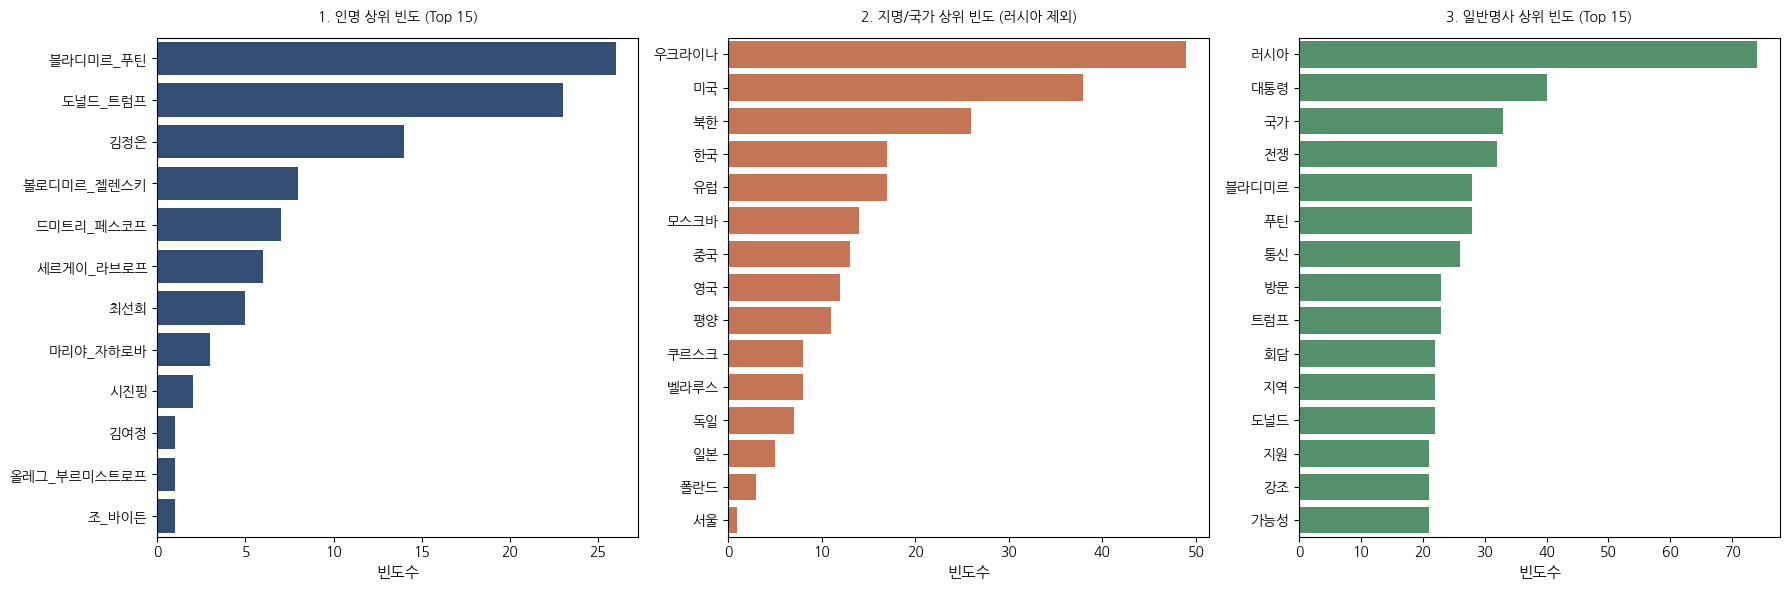


✅ 인명 15명 유지 + 지명에서만 러시아 제외 완료! 엑셀 파일('News_Frequency_Analysis_Fixed.xlsx') 다운로드 중...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ==============================================================================
# [수정된 코드] 인명은 상위 15명 유지 + 지명에서만 '러시아' 제외
# ==============================================================================
!apt-get install -y fonts-nanum -q

import re
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from wordcloud import WordCloud
from collections import Counter
from google.colab import files
import warnings
warnings.filterwarnings('ignore')

# 1. 코랩 나눔고딕 한글 폰트 설정
fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
font_prop = fm.FontProperties(fname='/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
plt.rc('font', family=font_prop.get_name())
plt.rcParams['axes.unicode_minus'] = False

# 2. 엑셀 데이터 로드
file_name = 'NewsResult_Preprocessed_Final.xlsx'
df = pd.read_excel(file_name, sheet_name=0)

# 3. 매핑 사전 정의
name_map = {
    '도널드 트럼프': '도널드_트럼프', '도널드': '도널드_트럼프', '트럼프': '도널드_트럼프',
    '블라디미르 푸틴': '블라디미르_푸틴', '블라디미르': '블라디미르_푸틴', '푸틴': '블라디미르_푸틴',
    '볼로디미르 젤렌스키': '볼로디미르_젤렌스키', '볼로디미르': '볼로디미르_젤렌스키', '젤렌스키': '볼로디미르_젤렌스키',
    '조 바이든': '조_바이든', '바이든': '조_바이든', '김정은': '김정은', '시진핑': '시진핑',
    '마리야 자하로바': '마리야_자하로바', '자하로바': '마리야_자하로바',
    '올레그 부르미스트로프': '올레그_부르미스트로프', '부르미스트로프': '올레그_부르미스트로프',
    '드미트리 페스코프': '드미트리_페스코프', '페스코프': '드미트리_페스코프',
    '세르게이 라브로프': '세르게이_라브로프', '라브로프': '세르게이_라브로프',
    '최선희': '최선희', '김여정': '김여정'
}

location_map = {
    '러시아': '러시아', '우크라이나': '우크라이나', '우크라': '우크라이나', '미국': '미국', '美': '미국',
    '북한': '북한', '北': '북한', '한국': '한국', '韓': '한국', '중국': '중국', '中': '중국',
    '일본': '일본', '日': '일본', '모스크바': '모스크바', '서울': '서울', '평양': '평양',
    '유럽': '유럽', '쿠르스크': '쿠르스크', '벨라루스': '벨라루스', '영국': '영국', '폴란드': '폴란드', '독일': '독일'
}

# 💡 일반명사 정제 시에만 쓸 독립된 불용어 세트 (인명/지명은 건드리지 않음)
stopwords_nouns = set([
    '현지시간', '현지', '시간', '보도', '기자', '관련', '위해', '대한', '통해', '이날', '최근', '지난', '측은', '대해', '모습'
])

# 4. 행 단위 정제 처리
def process_data(row):
    # 인명 결합 (정상적으로 모든 인물 수집)
    persons = []
    p_combined = f"{row.get('인물', '')}, {row.get('전처리_인명', '')}"
    for token in re.split(r'[,|\s]+', str(p_combined)):
        token = token.strip()
        if token in name_map:
            persons.append(name_map[token])
    persons = list(dict.fromkeys(persons))

    # 지명 결합 (여기서만 '러시아'를 제외 처리)
    locations = []
    l_combined = f"{row.get('위치', '')}, {row.get('전처리_지명국가', '')}"
    for token in re.split(r'[,|\s]+', str(l_combined)):
        token = token.strip()
        if token in location_map and token != '러시아':  # 지명에서 '러시아' 제외
            locations.append(location_map[token])
    locations = list(dict.fromkeys(locations))

    # 순수 일반명사만 추출
    nouns = []
    n_combined = f"{row.get('전처리_일반명사', '')} {row.get('키워드', '')}"
    for token in re.split(r'[,|\s]+', str(n_combined)):
        token = token.strip()
        if len(token) > 1 and not token.isdigit():
            if token not in stopwords_nouns and token not in persons and token not in locations:
                nouns.append(token)
    nouns = list(dict.fromkeys(nouns))

    return ", ".join(persons), ", ".join(locations), ", ".join(nouns)

res = df.apply(process_data, axis=1)
df['전처리_인명'] = [r[0] for r in res]
df['전처리_지명국가'] = [r[1] for r in res]
df['전처리_일반명사'] = [r[2] for r in res]

# 5. 빈도수 카운터 생성 (인명 카운터에는 아무것도 빼지 않음)
def get_clean_counter(series):
    words = []
    for text in series.dropna():
        for token in str(text).split(','):
            token = token.strip()
            if token:
                words.append(token)
    return Counter(words)

person_counts = get_clean_counter(df['전처리_인명'])
location_counts = get_clean_counter(df['전처리_지명국가'])
noun_counts = get_clean_counter(df['전처리_일반명사'])

df_person_freq = pd.DataFrame(person_counts.most_common(), columns=['인명', '빈도수'])
df_location_freq = pd.DataFrame(location_counts.most_common(), columns=['지명/국가', '빈도수'])
df_noun_freq = pd.DataFrame(noun_counts.most_common(), columns=['일반명사', '빈도수'])

# ==============================================================================
# [시각화 1] 막대그래프 출력 (인명 Top 15 정상 출력 확인)
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

data_list = [df_person_freq.head(15), df_location_freq.head(15), df_noun_freq.head(15)]
titles = ['1. 인명 상위 빈도 (Top 15)', '2. 지명/국가 상위 빈도 (러시아 제외)', '3. 일반명사 상위 빈도 (Top 15)']
colors = ['#2B4C7E', '#D96B43', '#4A9B68']

for ax, data, title, color in zip(axes, data_list, titles, colors):
    if not data.empty:
        col_name = data.columns[0]
        sns.barplot(data=data, x='빈도수', y=col_name, ax=ax, palette=[color]*len(data))
        ax.set_title(title, fontsize=14, fontweight='bold', fontproperties=font_prop, pad=12)
        ax.set_xlabel('빈도수', fontproperties=font_prop, fontsize=11)
        ax.set_ylabel('', fontproperties=font_prop)
        for tick in ax.get_yticklabels():
            tick.set_fontproperties(font_prop)

plt.tight_layout()
plt.savefig('1_frequency_bar_charts_fixed.png', dpi=300)
plt.show()

# ==============================================================================
# [엑셀 추출]
# ==============================================================================
output_file = 'News_Frequency_Analysis_Fixed.xlsx'
with pd.ExcelWriter(output_file, engine='openpyxl') as writer:
    df_person_freq.to_excel(writer, sheet_name='인명_빈도분석', index=False)
    df_location_freq.to_excel(writer, sheet_name='지명국가_빈도분석', index=False)
    df_noun_freq.to_excel(writer, sheet_name='일반명사_빈도분석', index=False)

print(f"\n✅ 인명 15명 유지 + 지명에서만 러시아 제외 완료! 엑셀 파일('{output_file}') 다운로드 중...")
files.download(output_file)

Reading package lists...
Building dependency tree...
Reading state information...
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.


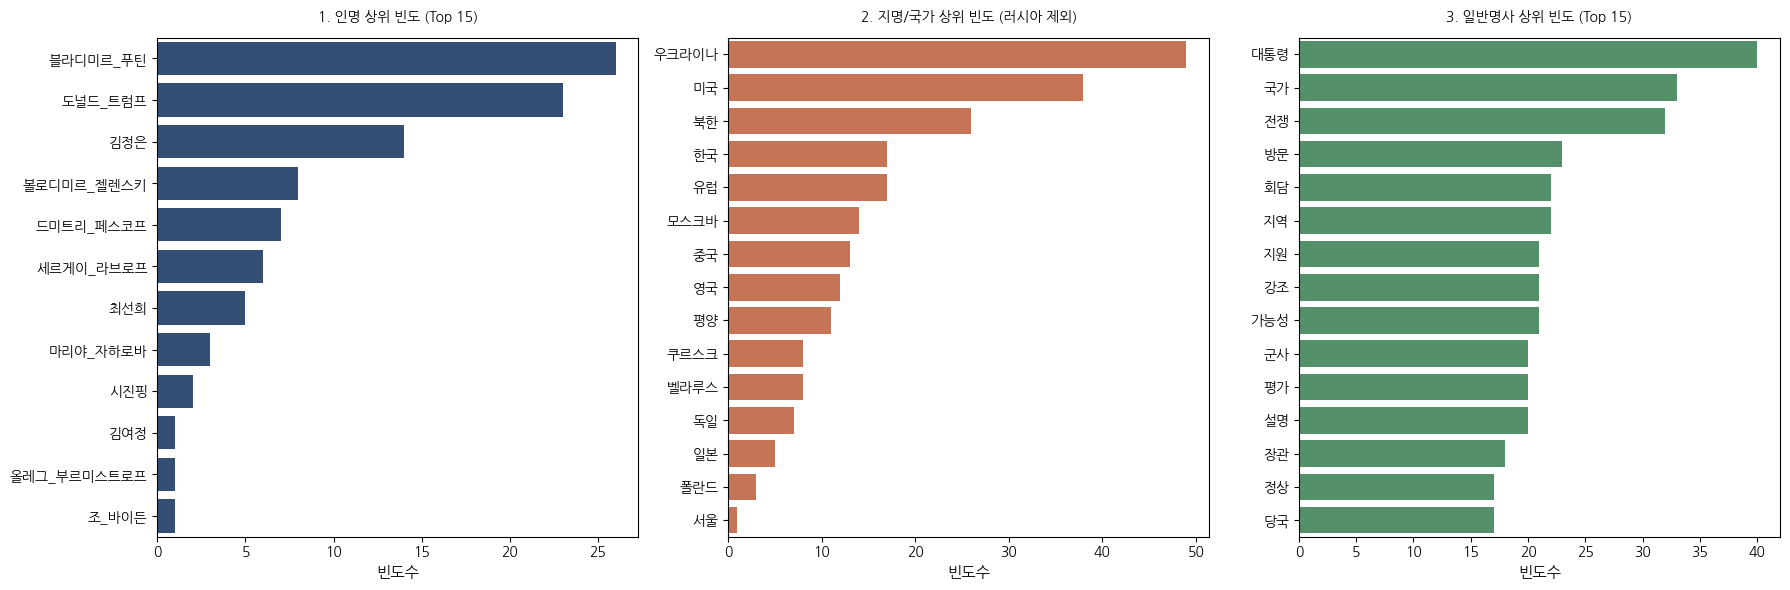


✅ 일반명사 인명 파편 제거 완료! 엑셀 파일('News_Frequency_Analysis_Clean.xlsx') 다운로드 중...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ==============================================================================
# [최종] 일반명사 내 인명/지명 조각('도널드', '트럼프', '푸틴' 등) 완벽 차단 코드
# ==============================================================================
!apt-get install -y fonts-nanum -q

import re
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from wordcloud import WordCloud
from collections import Counter
from google.colab import files
import warnings
warnings.filterwarnings('ignore')

# 1. 코랩 나눔고딕 한글 폰트 설정
fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
font_prop = fm.FontProperties(fname='/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
plt.rc('font', family=font_prop.get_name())
plt.rcParams['axes.unicode_minus'] = False

# 2. 엑셀 데이터 로드
file_name = 'NewsResult_Preprocessed_Final.xlsx'
df = pd.read_excel(file_name, sheet_name=0)

# 3. 매핑 사전 정의
name_map = {
    '도널드 트럼프': '도널드_트럼프', '도널드': '도널드_트럼프', '트럼프': '도널드_트럼프',
    '블라디미르 푸틴': '블라디미르_푸틴', '블라디미르': '블라디미르_푸틴', '푸틴': '블라디미르_푸틴',
    '볼로디미르 젤렌스키': '볼로디미르_젤렌스키', '볼로디미르': '볼로디미르_젤렌스키', '젤렌스키': '볼로디미르_젤렌스키',
    '조 바이든': '조_바이든', '바이든': '조_바이든', '김정은': '김정은', '시진핑': '시진핑',
    '마리야 자하로바': '마리야_자하로바', '자하로바': '마리야_자하로바',
    '올레그 부르미스트로프': '올레그_부르미스트로프', '부르미스트로프': '올레그_부르미스트로프',
    '드미트리 페스코프': '드미트리_페스코프', '페스코프': '드미트리_페스코프',
    '세르게이 라브로프': '세르게이_라브로프', '라브로프': '세르게이_라브로프',
    '최선희': '최선희', '김여정': '김여정'
}

location_map = {
    '러시아': '러시아', '우크라이나': '우크라이나', '우크라': '우크라이나', '미국': '미국', '美': '미국',
    '북한': '북한', '北': '북한', '한국': '한국', '韓': '한국', '중국': '중국', '中': '중국',
    '일본': '일본', '日': '일본', '모스크바': '모스크바', '서울': '서울', '평양': '평양',
    '유럽': '유럽', '쿠르스크': '쿠르스크', '벨라루스': '벨라루스', '영국': '영국', '폴란드': '폴란드', '독일': '독일'
}

# 💡 일반명사에 절대 나오면 안 되는 단어들 (불용어 + 통신/매체 + 인명/지명 파편들)
stopwords_nouns = set([
    '현지시간', '현지', '시간', '보도', '기자', '관련', '위해', '대한', '통해', '이날', '최근', '지난', '측은', '대해', '모습',
    '뉴스', '매체', '언론', '신문', '방송', '통신', '조선중앙통신', '로이터', '러시아',
    # 인명 파편들 차단
    '도널드', '트럼프', '블라디미르', '푸틴', '볼로디미르', '젤렌스키', '바이든', '조',
    '마리야', '자하로바', '올레그', '부르미스트로프', '드미트리', '페스코프', '세르게이', '라브로프', '최선희', '김여정', '김정은', '시진핑'
])

# 4. 행 단위 정제 처리
def process_data(row):
    # (1) 인명 결합
    persons = []
    p_combined = f"{row.get('인물', '')}, {row.get('전처리_인명', '')}"
    for token in re.split(r'[,|\s]+', str(p_combined)):
        token = token.strip()
        if token in name_map:
            persons.append(name_map[token])
    persons = list(dict.fromkeys(persons))

    # (2) 지명 결합 ('러시아' 제외)
    locations = []
    l_combined = f"{row.get('위치', '')}, {row.get('전처리_지명국가', '')}"
    for token in re.split(r'[,|\s]+', str(l_combined)):
        token = token.strip()
        if token in location_map and token != '러시아':
            locations.append(location_map[token])
    locations = list(dict.fromkeys(locations))

    # (3) 순수 일반명사 추출 (인명 파편, 통신사, 지명 파편 강력 차단)
    nouns = []
    n_combined = f"{row.get('전처리_일반명사', '')} {row.get('키워드', '')}"
    for token in re.split(r'[,|\s]+', str(n_combined)):
        token = token.strip()
        if len(token) > 1 and not token.isdigit():
            if token in stopwords_nouns:
                continue
            if any(kw in token for kw in ['통신', '매체', '언론', '신문', '방송', '뉴스']):
                continue
            # 인명/지명 원본 단어나 파편이면 무조건 제외
            if token in name_map or token in location_map:
                continue
            nouns.append(token)
    nouns = list(dict.fromkeys(nouns))

    return ", ".join(persons), ", ".join(locations), ", ".join(nouns)

res = df.apply(process_data, axis=1)
df['전처리_인명'] = [r[0] for r in res]
df['전처리_지명국가'] = [r[1] for r in res]
df['전처리_일반명사'] = [r[2] for r in res]

# 5. 빈도수 카운터 생성
def get_clean_counter(series):
    words = []
    for text in series.dropna():
        for token in str(text).split(','):
            token = token.strip()
            if token:
                words.append(token)
    return Counter(words)

person_counts = get_clean_counter(df['전처리_인명'])
location_counts = get_clean_counter(df['전처리_지명국가'])
noun_counts = get_clean_counter(df['전처리_일반명사'])

df_person_freq = pd.DataFrame(person_counts.most_common(), columns=['인명', '빈도수'])
df_location_freq = pd.DataFrame(location_counts.most_common(), columns=['지명/국가', '빈도수'])
df_noun_freq = pd.DataFrame(noun_counts.most_common(), columns=['일반명사', '빈도수'])

# ==============================================================================
# [시각화 1] 막대그래프 출력
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

data_list = [df_person_freq.head(15), df_location_freq.head(15), df_noun_freq.head(15)]
titles = ['1. 인명 상위 빈도 (Top 15)', '2. 지명/국가 상위 빈도 (러시아 제외)', '3. 일반명사 상위 빈도 (Top 15)']
colors = ['#2B4C7E', '#D96B43', '#4A9B68']

for ax, data, title, color in zip(axes, data_list, titles, colors):
    if not data.empty:
        col_name = data.columns[0]
        sns.barplot(data=data, x='빈도수', y=col_name, ax=ax, palette=[color]*len(data))
        ax.set_title(title, fontsize=14, fontweight='bold', fontproperties=font_prop, pad=12)
        ax.set_xlabel('빈도수', fontproperties=font_prop, fontsize=11)
        ax.set_ylabel('', fontproperties=font_prop)
        for tick in ax.get_yticklabels():
            tick.set_fontproperties(font_prop)

plt.tight_layout()
plt.savefig('1_frequency_bar_charts_clean_noun.png', dpi=300)
plt.show()

# ==============================================================================
# [엑셀 추출]
# ==============================================================================
output_file = 'News_Frequency_Analysis_Clean.xlsx'
with pd.ExcelWriter(output_file, engine='openpyxl') as writer:
    df_person_freq.to_excel(writer, sheet_name='인명_빈도분석', index=False)
    df_location_freq.to_excel(writer, sheet_name='지명국가_빈도분석', index=False)
    df_noun_freq.to_excel(writer, sheet_name='일반명사_빈도분석', index=False)

print(f"\n✅ 일반명사 인명 파편 제거 완료! 엑셀 파일('{output_file}') 다운로드 중...")
files.download(output_file)

In [ ]:
# ==============================================================================
# [2단계] LDA 토픽 모델링 코드 (정제 완료 데이터 기반)
# ==============================================================================
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from google.colab import files
import warnings
warnings.filterwarnings('ignore')

# 1. 1단계에서 정제한 최종 데이터 불러오기
file_name = 'NewsResult_Preprocessed_Final.xlsx'
df = pd.read_excel(file_name, sheet_name=0)

# 2. 문서별 키워드 결합 (인명 + 지명/국가 + 일반명사)
documents = []
for idx, row in df.iterrows():
    p = str(row['전처리_인명']) if pd.notna(row['전처리_인명']) else ''
    l = str(row['전처리_지명국가']) if pd.notna(row['전처리_지명국가']) else ''
    n = str(row['전처리_일반명사']) if pd.notna(row['전처리_일반명사']) else ''
    combined = f"{p} {l} {n}"
    documents.append(combined)

# 3. DTM (Document-Term Matrix) 생성
vectorizer = CountVectorizer(max_df=0.85, min_df=2, token_pattern=r'(?u)\b[가-힣a-zA-Z_]{2,}\b')
dtm = vectorizer.fit_transform(documents)

# 4. LDA 토픽 모델링 (토픽 개수 = 3개)
NUM_TOPICS = 3
lda = LatentDirichletAllocation(n_components=NUM_TOPICS, random_state=42, max_iter=25)
lda.fit(dtm)

# 5. 토픽별 상위 키워드 추출
feature_names = vectorizer.get_feature_names_out()
print(f"📌 [추출된 {NUM_TOPICS}개 토픽별 상위 키워드]\n")

topic_names = {
    0: "Topic 1: 러-우 전쟁 및 군사 전황",
    1: "Topic 2: 정상 외교 및 종전 협상",
    2: "Topic 3: 동북아 안보 공조 및 제재"
}

for topic_idx, topic in enumerate(lda.components_):
    top_features_ind = topic.argsort()[:-11:-1]
    top_features = [feature_names[i] for i in top_features_ind]
    print(f"• {topic_names[topic_idx]}")
    print(f"  키워드: {', '.join(top_features)}\n")

# 6. 각 기사별 주요 토픽 및 확율 계산
doc_topic_dist = lda.transform(dtm)
df['주요_토픽_번호'] = doc_topic_dist.argmax(axis=1) + 1
df['주요_토픽_명칭'] = [topic_names[i] for i in doc_topic_dist.argmax(axis=1)]

# 토픽별 기사 분포 확인
print("📌 [토픽별 기사 수 분포]")
print(df['주요_토픽_명칭'].value_counts())

# 7. 결과 저장 및 다운로드
output_excel = 'News_Topic_Modeling_Result.xlsx'
df.to_excel(output_excel, index=False)

print(f"\n✅ 토픽 모델링 결과 파일('{output_excel}') 생성이 완료되었습니다.")
files.download(output_excel)

📌 [추출된 3개 토픽별 상위 키워드]

• Topic 1: 러-우 전쟁 및 군사 전황
  키워드: 대통령, 미국, 도널드, 트럼프, 우크라이나, 현지, 시간, 푸틴, 블라디미르, 전쟁

• Topic 2: 정상 외교 및 종전 협상
  키워드: 북한, 우크라이나, 현지, 시간, 통신, 김정은, 국무위원, 드론, 매체, 지역

• Topic 3: 동북아 안보 공조 및 제재
  키워드: 평양, 시간, 현지, 북한, 외무, 국제, 발생, 선수, 방문, 국방

📌 [토픽별 기사 수 분포]
주요_토픽_명칭
Topic 2: 정상 외교 및 종전 협상     31
Topic 1: 러-우 전쟁 및 군사 전황    23
Topic 3: 동북아 안보 공조 및 제재    20
Name: count, dtype: int64

✅ 토픽 모델링 결과 파일('News_Topic_Modeling_Result.xlsx') 생성이 완료되었습니다.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Reading package lists...
Building dependency tree...
Reading state information...
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.


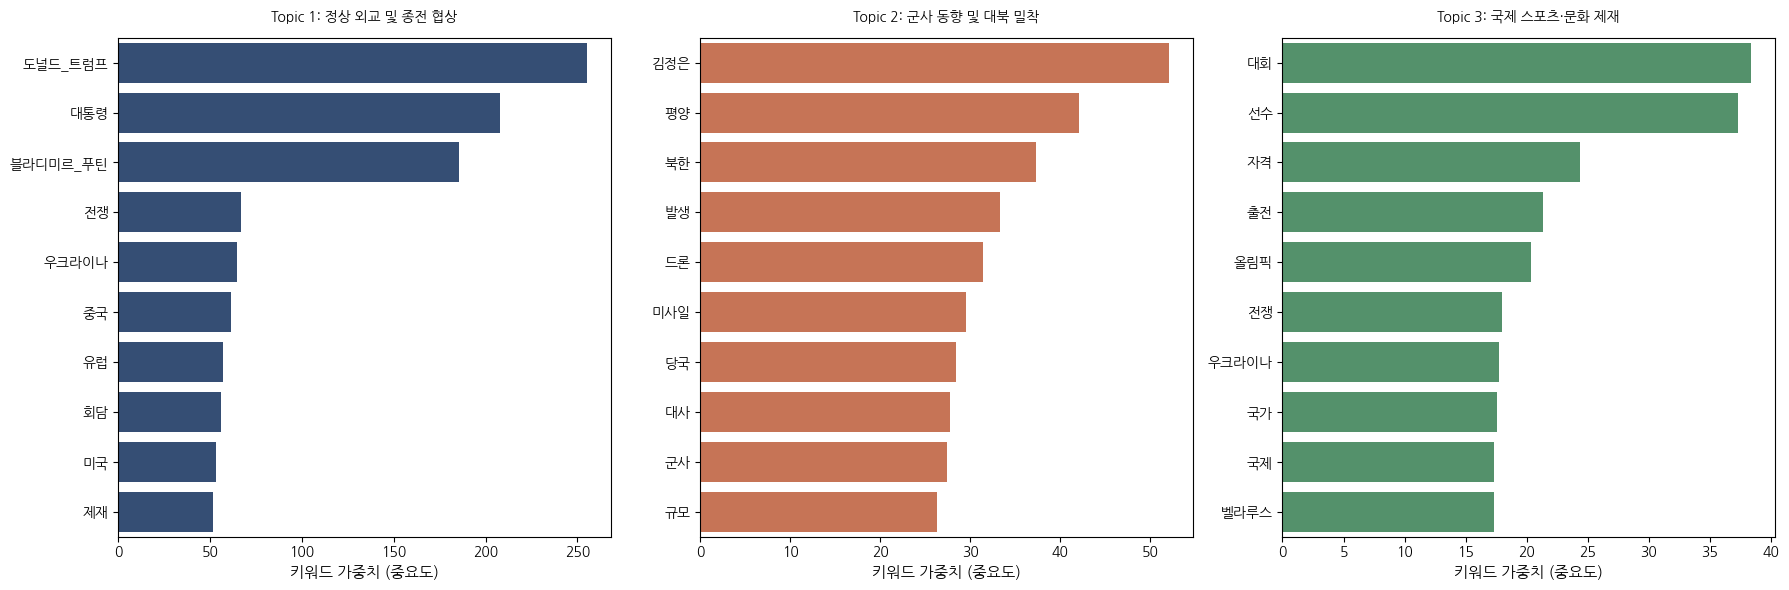

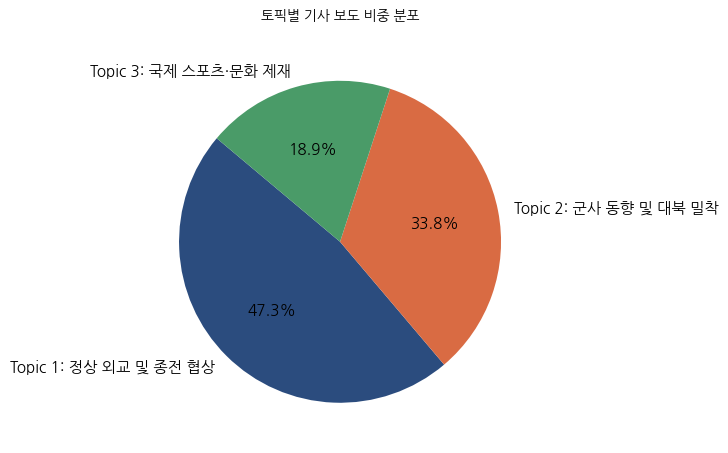


✅ 토픽 모델링 재정제 완료! 결과 파일('News_Topic_Modeling_Result_Fixed.xlsx')이 다운로드됩니다.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ==============================================================================
# [2단계] LDA 토픽 모델링 통합 코드 (인명 결합 완벽 반영 & 코랩 시각화)
# ==============================================================================
!apt-get install -y fonts-nanum -q

import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from google.colab import files
import warnings
warnings.filterwarnings('ignore')

# 1. 한글 폰트 설정
fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
font_prop = fm.FontProperties(fname='/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
plt.rc('font', family=font_prop.get_name())
plt.rcParams['axes.unicode_minus'] = False

# 2. 전처리 데이터 로드
file_name = 'NewsResult_Preprocessed_Final.xlsx'
df = pd.read_excel(file_name, sheet_name=0)

# 3. 토픽 모델링 학습용 텍스트 생성 (인명 결합 강제 적용)
name_map = {
    '도널드 트럼프': '도널드_트럼프', '도널드': '도널드_트럼프', '트럼프': '도널드_트럼프',
    '블라디미르 푸틴': '블라디미르_푸틴', '블라디미르': '블라디미르_푸틴', '푸틴': '블라디미르_푸틴',
    '볼로디미르 젤렌스키': '볼로디미르_젤렌스키', '볼로디미르': '볼로디미르_젤렌스키', '젤렌스키': '볼로디미르_젤렌스키',
    '조 바이든': '조_바이든', '바이든': '조_바이든', '김정은': '김정은', '시진핑': '시진핑'
}

stopwords = set(['현지시간', '현지', '시간', '보도', '기자', '관련', '위해', '대한', '통해', '이날', '최근', '지난', '측은', '대해'])

documents = []
for idx, row in df.iterrows():
    tokens = []
    # (1) 인명
    p_str = f"{row.get('인물', '')} {row.get('전처리_인명', '')}"
    for t in re.split(r'[,|\s]+', str(p_str)):
        t = t.strip()
        if t in name_map:
            tokens.append(name_map[t])

    # (2) 지명/국가
    l_str = f"{row.get('위치', '')} {row.get('전처리_지명국가', '')}"
    for t in re.split(r'[,|\s]+', str(l_str)):
        t = t.strip()
        if t in ['러시아', '우크라이나', '미국', '북한', '한국', '중국', '유럽', '모스크바', '평양']:
            tokens.append(t)

    # (3) 일반명사 (단독 낱개 인명 재변환)
    n_str = f"{row.get('전처리_일반명사', '')} {row.get('키워드', '')}"
    for t in re.split(r'[,|\s]+', str(n_str)):
        t = t.strip()
        if len(t) > 1 and not t.isdigit() and t not in stopwords:
            if t in name_map:
                tokens.append(name_map[t])
            elif t not in ['러시아', '우크라이나', '미국', '북한', '한국']:
                tokens.append(t)

    documents.append(" ".join(tokens))

# 4. DTM 생성 & LDA 토픽 모델링 (3개 토픽)
vectorizer = CountVectorizer(max_df=0.85, min_df=2, token_pattern=r'(?u)\b[가-힣a-zA-Z_]{2,}\b')
dtm = vectorizer.fit_transform(documents)

NUM_TOPICS = 3
lda = LatentDirichletAllocation(n_components=NUM_TOPICS, random_state=42, max_iter=25)
lda.fit(dtm)

feature_names = vectorizer.get_feature_names_out()

topic_names = [
    "Topic 1: 정상 외교 및 종전 협상",
    "Topic 2: 군사 동향 및 대북 밀착",
    "Topic 3: 국제 스포츠·문화 제재"
]

# 기사별 주요 토픽 할당
doc_topic_dist = lda.transform(dtm)
df['주요_토픽_번호'] = doc_topic_dist.argmax(axis=1) + 1
df['주요_토픽_명칭'] = [topic_names[i] for i in doc_topic_dist.argmax(axis=1)]

# ==============================================================================
# [시각화 1] 토픽별 주요 키워드 상위 10개 막대그래프 (인명 결합 확인)
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
bar_colors = ['#2B4C7E', '#D96B43', '#4A9B68']

for idx, topic in enumerate(lda.components_):
    top_indices = topic.argsort()[:-11:-1]
    top_words = [feature_names[i] for i in top_indices]
    top_weights = topic[top_indices]

    ax = axes[idx]
    sns.barplot(x=top_weights, y=top_words, ax=ax, palette=[bar_colors[idx]]*10)
    ax.set_title(topic_names[idx], fontsize=13, fontweight='bold', fontproperties=font_prop, pad=12)
    ax.set_xlabel('키워드 가중치 (중요도)', fontproperties=font_prop, fontsize=11)
    ax.set_ylabel('', fontproperties=font_prop)
    for tick in ax.get_yticklabels():
        tick.set_fontproperties(font_prop)

plt.tight_layout()
plt.savefig('2_topic_keywords_bar_charts_fixed.png', dpi=300)
plt.show()

# ==============================================================================
# [시각화 2] 토픽별 기사 보도 비중 파이차트
# ==============================================================================
plt.figure(figsize=(7, 7))
topic_counts = df['주요_토픽_명칭'].value_counts()

plt.pie(
    topic_counts,
    labels=topic_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=bar_colors,
    textprops={'fontproperties': font_prop, 'fontsize': 11}
)
plt.title('토픽별 기사 보도 비중 분포', fontsize=14, fontweight='bold', fontproperties=font_prop, pad=15)
plt.tight_layout()
plt.savefig('2_topic_distribution_pie_chart_fixed.png', dpi=300)
plt.show()

# ==============================================================================
# [엑셀 저장 및 다운로드]
# ==============================================================================
output_excel = 'News_Topic_Modeling_Result_Fixed.xlsx'

with pd.ExcelWriter(output_excel, engine='openpyxl') as writer:
    df.to_excel(writer, sheet_name='기사별_토픽분석결과', index=False)

    topic_summary = []
    for idx, topic in enumerate(lda.components_):
        top_indices = topic.argsort()[:-16:-1]
        top_words = [feature_names[i] for i in top_indices]
        topic_summary.append({
            '토픽 번호': f"Topic {idx+1}",
            '토픽 명칭': topic_names[idx],
            '상위 키워드(Top 15)': ", ".join(top_words)
        })
    pd.DataFrame(topic_summary).to_excel(writer, sheet_name='토픽별_주요키워드요약', index=False)

print(f"\n✅ 토픽 모델링 재정제 완료! 결과 파일('{output_excel}')이 다운로드됩니다.")
files.download(output_excel)

Reading package lists...
Building dependency tree...
Reading state information...
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.


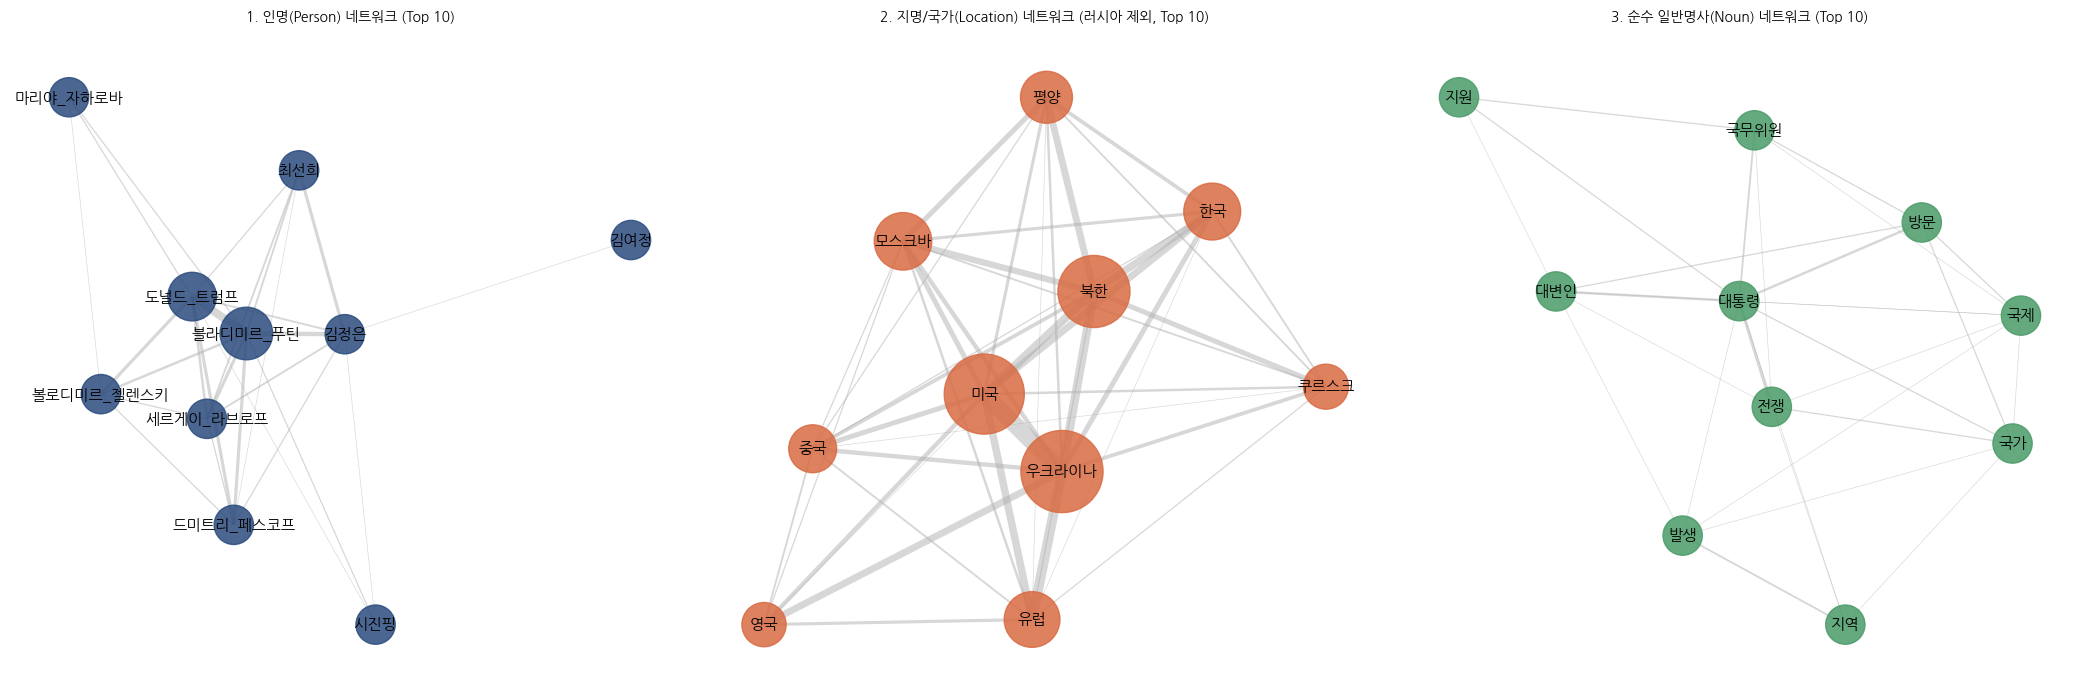


✅ Top 10 통일 및 조선/중앙 차단 완료! 결과 엑셀('News_3Category_Top10_Networks_Final.xlsx') 다운로드 중...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ==============================================================================
# [최종] 3개 범주별 상위 네트워크 분석 통합 코드 (Top 10 통일 + 조선/중앙 차단)
# ==============================================================================
!apt-get install -y fonts-nanum -q

import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import networkx as nx
from collections import Counter
from google.colab import files
import warnings
warnings.filterwarnings('ignore')

# 1. 한글 폰트 설정
fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
font_prop = fm.FontProperties(fname='/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
plt.rc('font', family=font_prop.get_name())
plt.rcParams['axes.unicode_minus'] = False

# 2. 전처리 완료 데이터 로드
file_name = 'NewsResult_Preprocessed_Final.xlsx'
df = pd.read_excel(file_name, sheet_name=0)

# 3. 매핑 사전 설정
name_map = {
    '도널드 트럼프': '도널드_트럼프', '도널드': '도널드_트럼프', '트럼프': '도널드_트럼프',
    '블라디미르 푸틴': '블라디미르_푸틴', '블라디미르': '블라디미르_푸틴', '푸틴': '블라디미르_푸틴',
    '볼로디미르 젤렌스키': '볼로디미르_젤렌스키', '볼로디미르': '볼로디미르_젤렌스키', '젤렌스키': '볼로디미르_젤렌스키',
    '조 바이든': '조_바이든', '바이든': '조_바이든', '김정은': '김정은', '시진핑': '시진핑',
    '마리야 자하로바': '마리야_자하로바', '자하로바': '마리야_자하로바',
    '올레그 부르미스트로프': '올레그_부르미스트로프', '부르미스트로프': '올레그_부르미스트로프',
    '드미트리 페스코프': '드미트리_페스코프', '페스코프': '드미트리_페스코프',
    '세르게이 라브로프': '세르게이_라브로프', '라브로프': '세르게이_라브로프',
    '최선희': '최선희', '김여정': '김여정'
}

location_map = {
    '러시아': '러시아', '우크라이나': '우크라이나', '우크라': '우크라이나', '미국': '미국', '美': '미국',
    '북한': '북한', '北': '북한', '한국': '한국', '韓': '한국', '중국': '중국', '中': '중국',
    '일본': '일본', '日': '일본', '모스크바': '모스크바', '서울': '서울', '평양': '평양',
    '유럽': '유럽', '쿠르스크': '쿠르스크', '벨라루스': '벨라루스', '영국': '영국', '폴란드': '폴란드', '독일': '독일'
}

# 💡 일반명사 네트워크에서 차단할 불용어 (조선, 중앙 및 언론사 키워드 + 인명/지명 파편)
stopwords_nouns = set([
    '현지시간', '현지', '시간', '보도', '기자', '관련', '위해', '대한', '통해',
    '이날', '최근', '지난', '측은', '대해', '뉴스', '매체', '언론', '신문', '방송', '통신',
    '조선중앙통신', '로이터', '러시아', '조선', '중앙',
    # 인명 파편들 차단
    '도널드', '트럼프', '블라디미르', '푸틴', '볼로디미르', '젤렌스키', '바이든', '조',
    '마리야', '자하로바', '올레그', '부르미스트로프', '드미트리', '페스코프', '세르게이', '라브로프', '최선희', '김여정', '김정은', '시진핑'
])

# 4. 3가지 범주별 독립 리스트 추출
persons_docs, locations_docs, pure_nouns_docs = [], [], []

for idx, row in df.iterrows():
    # (1) 인명 리스트
    p_tokens = []
    p_str = f"{row.get('인물', '')} {row.get('전처리_인명', '')}"
    for t in re.split(r'[,|\s]+', str(p_str)):
        t = t.strip()
        if t in name_map:
            p_tokens.append(name_map[t])
    persons_docs.append(list(set(p_tokens)))

    # (2) 지명/국가 리스트 ('러시아' 배제)
    l_tokens = []
    l_str = f"{row.get('위치', '')} {row.get('전처리_지명국가', '')}"
    for t in re.split(r'[,|\s]+', str(l_str)):
        t = t.strip()
        if t in location_map and t != '러시아':
            l_tokens.append(location_map[t])
    locations_docs.append(list(set(l_tokens)))

    # (3) 순수 일반명사 리스트 (조선, 중앙, 통신사, 인명/지명 파편 완벽 차단)
    n_tokens = []
    n_str = str(row.get('전처리_일반명사', ''))
    for t in re.split(r'[,|\s]+', n_str):
        t = t.strip()
        if len(t) > 1 and not t.isdigit():
            if t in stopwords_nouns:
                continue
            if any(keyword in t for keyword in ['통신', '매체', '언론', '신문', '방송', '뉴스', '조선', '중앙']):
                continue
            if t in name_map or t in location_map:
                continue
            n_tokens.append(t)
    pure_nouns_docs.append(list(set(n_tokens)))

# 5. 상위 N개 노드 중심 네트워크 구축 함수 (top_n=10으로 통일)
def build_top_network(docs, top_n=10):
    G_raw = nx.Graph()
    all_words = []
    for doc in docs:
        all_words.extend(doc)
        for i in range(len(doc)):
            for j in range(i + 1, len(doc)):
                w1, w2 = doc[i], doc[j]
                if G_raw.has_edge(w1, w2):
                    G_raw[w1][w2]['weight'] += 1
                else:
                    G_raw.add_edge(w1, w2, weight=1)

    counts = Counter(all_words)
    top_nodes = [w for w, c in counts.most_common(top_n)]
    G_top = G_raw.subgraph(top_nodes).copy()
    return G_top

# 인명, 지명, 일반명사 모두 Top 10으로 통일 생성
G_p_top = build_top_network(persons_docs, top_n=10)
G_l_top = build_top_network(locations_docs, top_n=10)
G_n_top = build_top_network(pure_nouns_docs, top_n=10)

# ==============================================================================
# [시각화]
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(21, 7))

networks = [
    ("1. 인명(Person) 네트워크 (Top 10)", G_p_top, '#2B4C7E'),
    ("2. 지명/국가(Location) 네트워크 (러시아 제외, Top 10)", G_l_top, '#D96B43'),
    ("3. 순수 일반명사(Noun) 네트워크 (Top 10)", G_n_top, '#4A9B68')
]

for idx, (title, G_sub, color) in enumerate(networks):
    ax = axes[idx]
    if len(G_sub.nodes) > 0:
        pos = nx.spring_layout(G_sub, k=1.25, seed=42)
        deg = dict(G_sub.degree(weight='weight'))

        node_sizes = [max(deg.get(n, 1) * 35, 800) for n in G_sub.nodes()]
        edge_weights = [G_sub[u][v]['weight'] * 0.45 for u, v in G_sub.edges()]

        nx.draw_networkx_nodes(G_sub, pos, node_size=node_sizes, node_color=color, alpha=0.85, ax=ax)
        if len(G_sub.edges()) > 0:
            nx.draw_networkx_edges(G_sub, pos, width=edge_weights, edge_color='#B0B0B0', alpha=0.5, ax=ax)
        nx.draw_networkx_labels(G_sub, pos, font_family=font_prop.get_name(), font_size=11, font_weight='bold', ax=ax)

    ax.set_title(title, fontsize=14, fontweight='bold', fontproperties=font_prop, pad=15)
    ax.axis('off')

plt.tight_layout()
plt.savefig('3_category_top10_perfect_networks.png', dpi=300)
plt.show()

# ==============================================================================
# [엑셀 저장]
# ==============================================================================
output_excel = 'News_3Category_Top10_Networks_Final.xlsx'
with pd.ExcelWriter(output_excel, engine='openpyxl') as writer:
    for name, G_sub in [('인명_상위네트워크', G_p_top), ('지명국가_상위네트워크', G_l_top), ('순수일반명사_상위네트워크', G_n_top)]:
        if len(G_sub.nodes) > 0:
            deg_c = nx.degree_centrality(G_sub)
            wt_deg = dict(G_sub.degree(weight='weight'))
            pd.DataFrame({
                '노드명': list(G_sub.nodes()),
                '가중연결정도': [wt_deg[n] for n in G_sub.nodes()],
                '연결중심성': [round(deg_c[n], 4) for n in G_sub.nodes()]
            }).sort_values(by='가중연결정도', ascending=False).to_excel(writer, sheet_name=name, index=False)

print(f"\n✅ Top 10 통일 및 조선/중앙 차단 완료! 결과 엑셀('{output_excel}') 다운로드 중...")
files.download(output_excel)

Reading package lists...
Building dependency tree...
Reading state information...
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.


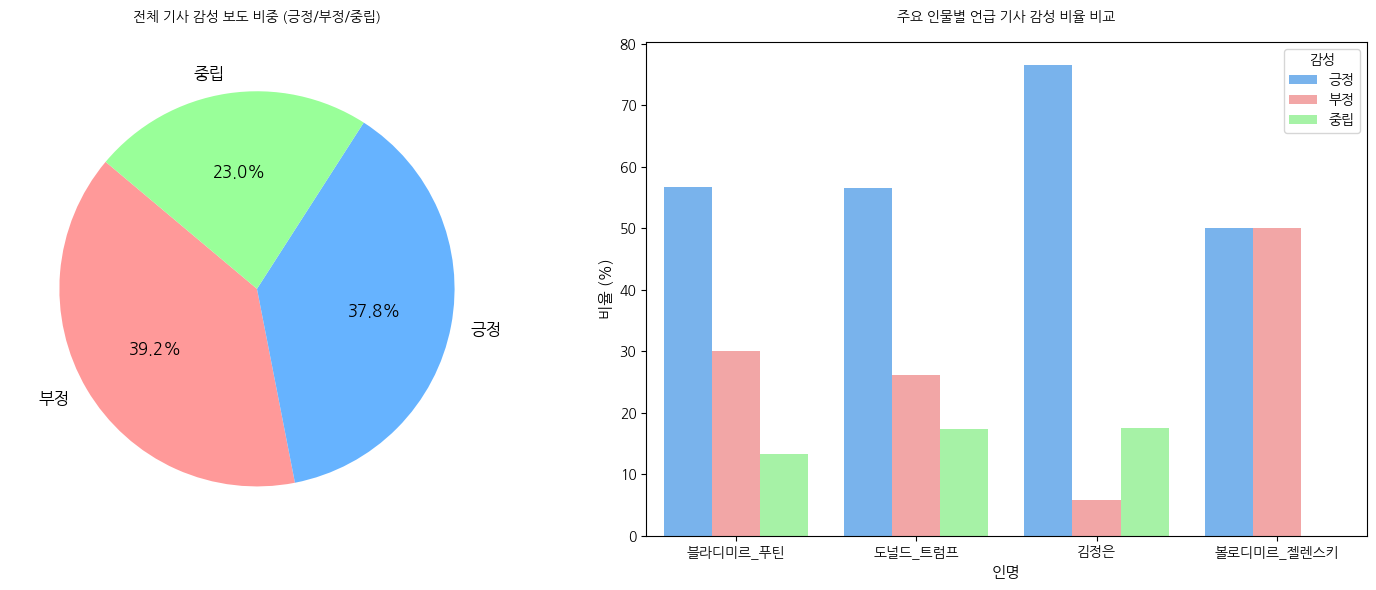


✅ 감성 분석 시각화 완료 및 최종 결과 엑셀('News_Sentiment_Analysis_Result_Final.xlsx') 다운로드가 완료되었습니다.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ==============================================================================
# [4단계] 감성 분석 통합 코드 ('러시아' 불용어 제거 + 인명 결합 + 코랩 시각화 + 엑셀 저장)
# ==============================================================================
!apt-get install -y fonts-nanum -q

import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from google.colab import files
import warnings
warnings.filterwarnings('ignore')

# 1. 코랩 나눔고딕 한글 폰트 설정
fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
font_prop = fm.FontProperties(fname='/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
plt.rc('font', family=font_prop.get_name())
plt.rcParams['axes.unicode_minus'] = False

# 2. 전처리 완료 데이터 로드
file_name = 'NewsResult_Preprocessed_Final.xlsx'
df = pd.read_excel(file_name, sheet_name=0)

# 3. 매핑 및 불용어 사전 설정 ('러시아' 불용어 포함)
name_map = {
    '도널드 트럼프': '도널드_트럼프', '도널드': '도널드_트럼프', '트럼프': '도널드_트럼프',
    '블라디미르 푸틴': '블라디미르_푸틴', '블라디미르': '블라디미르_푸틴', '푸틴': '블라디미르_푸틴',
    '볼로디미르 젤렌스키': '볼로디미르_젤렌스키', '볼로디미르': '볼로디미르_젤렌스키', '젤렌스키': '볼로디미르_젤렌스키',
    '조 바이든': '조_바이든', '바이든': '조_바이든', '김정은': '김정은', '시진핑': '시진핑',
    '마리야 자하로바': '마리야_자하로바', '드미트리 페스코프': '드미트리_페스코프', '세르게이 라브로프': '세르게이_라브로프'
}

location_map = {
    '우크라이나': '우크라이나', '미국': '미국', '북한': '북한',
    '한국': '한국', '중국': '중국', '유럽': '유럽', '모스크바': '모스크바', '평양': '평양', '쿠르스크': '쿠르스크'
    # '러시아' 제외
}

stopwords = set(['러시아', '현지시간', '현지', '시간', '보도', '기자', '관련', '위해', '대한', '통해', '이날', '최근', '지난', '측은', '대해'])

# 4. 범주별 데이터 재정제 함수
def clean_row(row):
    # 인명 결합
    persons = []
    p_str = f"{row.get('인물', '')} {row.get('전처리_인명', '')}"
    for t in re.split(r'[,|\s]+', str(p_str)):
        t = t.strip()
        if t in name_map:
            persons.append(name_map[t])

    # 지명 ('러시아' 제거)
    locations = []
    l_str = f"{row.get('위치', '')} {row.get('전처리_지명국가', '')}"
    for t in re.split(r'[,|\s]+', str(l_str)):
        t = t.strip()
        if t in location_map and t != '러시아':
            locations.append(location_map[t])

    # 일반명사 (인명, 지명, 불용어 배제)
    nouns = []
    n_str = f"{row.get('전처리_일반명사', '')} {row.get('키워드', '')}"
    for t in re.split(r'[,|\s]+', str(n_str)):
        t = t.strip()
        if len(t) > 1 and not t.isdigit() and t not in stopwords:
            if t in name_map:
                persons.append(name_map[t])
            elif t not in ['우크라이나', '미국', '북한', '한국', '중국', '유럽', '러시아']:
                nouns.append(t)

    return ", ".join(list(dict.fromkeys(persons))), ", ".join(list(dict.fromkeys(locations))), ", ".join(list(dict.fromkeys(nouns)))

res = df.apply(clean_row, axis=1)
df['전처리_인명'] = [r[0] for r in res]
df['전처리_지명국가'] = [r[1] for r in res]
df['전처리_일반명사'] = [r[2] for r in res]

# 5. 감성 분석 사전 구축 (외교/국제 보도 특화 KnuSentiLex 기반)
pos_words = set(['협력', '대화', '평화', '개선', '종전', '지원', '합의', '회담', '우호', '안정', '완화', '도움', '성공', '복구', '희망', '유화', '기여', '발전', '수용'])
neg_words = set(['전쟁', '위협', '압박', '제재', '사망', '파병', '공격', '침범', '침략', '항의', '갈등', '대립', '긴장', '희생', '우려', '격화', '폭발', '폭행', '구속', '마찰'])

def calc_sentiment(row):
    tokens = str(row['전처리_일반명사']).split(',') + str(row['제목']).split()
    tokens = [t.strip() for t in tokens if t.strip()]

    p_score = sum(1 for t in tokens if t in pos_words)
    n_score = sum(1 for t in tokens if t in neg_words)

    total = p_score + n_score
    if total == 0:
        return 0.0, '중립'

    score = (p_score - n_score) / (p_score + n_score)
    if score > 0.15:
        label = '긍정'
    elif score < -0.15:
        label = '부정'
    else:
        label = '중립'
    return round(score, 2), label

sent_res = df.apply(calc_sentiment, axis=1)
df['감성_점수'] = [r[0] for r in sent_res]
df['감성_라벨'] = [r[1] for r in sent_res]

# ==============================================================================
# [시각화 1] 전체 기사 감성 분포 (파이차트) & 주요 인물별 감성 비교 (막대그래프)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# (1) 전체 감성 파이차트
s_counts = df['감성_라벨'].value_counts()
colors = ['#ff9999', '#66b3ff', '#99ff99'] # 부정, 긍정, 중립
axes[0].pie(
    s_counts, labels=s_counts.index, autopct='%1.1f%%', startangle=140, colors=colors,
    textprops={'fontproperties': font_prop, 'fontsize': 12}
)
axes[0].set_title('전체 기사 감성 보도 비중 (긍정/부정/중립)', fontsize=14, fontweight='bold', fontproperties=font_prop, pad=15)

# (2) 주요 인물별 감성 비율 집계
person_list = ['블라디미르_푸틴', '도널드_트럼프', '김정은', '볼로디미르_젤렌스키']
person_sent_data = []

for p in person_list:
    sub = df[df['전처리_인명'].str.contains(p, na=False)]
    if len(sub) > 0:
        person_sent_data.append({
            '인명': p,
            '긍정': round((sub['감성_라벨'] == '긍정').mean() * 100, 1),
            '부정': round((sub['감성_라벨'] == '부정').mean() * 100, 1),
            '중립': round((sub['감성_라벨'] == '중립').mean() * 100, 1)
        })

df_ps = pd.DataFrame(person_sent_data)
df_ps_melted = df_ps.melt(id_vars=['인명'], value_vars=['긍정', '부정', '중립'], var_name='감성', value_name='비율(%)')

sns.barplot(data=df_ps_melted, x='인명', y='비율(%)', hue='감성', ax=axes[1], palette=['#66b3ff', '#ff9999', '#99ff99'])
axes[1].set_title('주요 인물별 언급 기사 감성 비율 비교', fontsize=14, fontweight='bold', fontproperties=font_prop, pad=15)
axes[1].set_xlabel('인명', fontproperties=font_prop, fontsize=11)
axes[1].set_ylabel('비율 (%)', fontproperties=font_prop, fontsize=11)
axes[1].legend(title='감성', prop=font_prop)
for tick in axes[1].get_yticklabels():
    tick.set_fontproperties(font_prop)
for tick in axes[1].get_xticklabels():
    tick.set_fontproperties(font_prop)

plt.tight_layout()
plt.savefig('4_sentiment_analysis_final.png', dpi=300)
plt.show()

# ==============================================================================
# [엑셀 추출] 최종 감성 분석 결과 포함 파일 저장
# ==============================================================================
output_excel = 'News_Sentiment_Analysis_Result_Final.xlsx'

with pd.ExcelWriter(output_excel, engine='openpyxl') as writer:
    # 1. 전체 기사별 감성점수 및 라벨
    df[['뉴스 식별자', '일자', '언론사', '제목', '전처리_인명', '전처리_지명국가', '전처리_일반명사', '감성_점수', '감성_라벨', 'URL']].to_excel(writer, sheet_name='기사별_감성분석결과', index=False)

    # 2. 주요 인물별 감성 비율 요약 시트
    df_ps.to_excel(writer, sheet_name='주요인물별_감성비율요약', index=False)

print(f"\n✅ 감성 분석 시각화 완료 및 최종 결과 엑셀('{output_excel}') 다운로드가 완료되었습니다.")
files.download(output_excel)